## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.08MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 6.86MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.6MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 10)
test_model(model)

Epoch 1/10, Loss: 2.012
Epoch 2/10, Loss: 1.729
Epoch 3/10, Loss: 1.627
Epoch 4/10, Loss: 1.596
Epoch 5/10, Loss: 1.582
Epoch 6/10, Loss: 1.572
Epoch 7/10, Loss: 1.566
Epoch 8/10, Loss: 1.561
Epoch 9/10, Loss: 1.557
Epoch 10/10, Loss: 1.553
Accuracy on images: 92.76


### Write the interval analysis for the simple model

eps=0 (should equal clean accuracy): 92.76
eps = 0.01   verified accuracy = 68.81%
eps = 0.02   verified accuracy = 22.54%
eps = 0.03   verified accuracy = 3.95%
eps = 0.04   verified accuracy = 0.40%
eps = 0.05   verified accuracy = 0.01%
eps = 0.06   verified accuracy = 0.00%
eps = 0.07   verified accuracy = 0.00%
eps = 0.08   verified accuracy = 0.00%
eps = 0.09   verified accuracy = 0.00%
eps = 0.10   verified accuracy = 0.00%


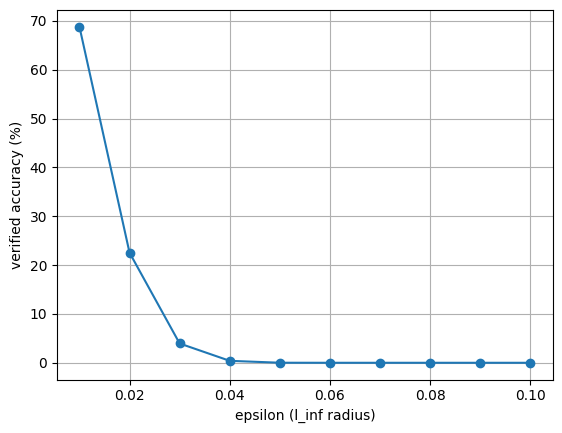

In [4]:
def interval_verify(model, x, y, eps):
    """Interval analysis for Normalize -> fc -> ReLU -> fc2, plus an output layer f_y - f_j.
    x: (B,1,28,28) images in [0,1]; y: (B,) labels. Returns bool tensor (B,): verified?"""
    net = model[1]
    B = x.shape[0]
    x = x.view(B, -1)

    l = (x - eps).clamp(0, 1)
    u = (x + eps).clamp(0, 1)

    l = (l - 0.1307) / 0.3081
    u = (u - 0.1307) / 0.3081

    # fc (affine layer): center/radius form
    W, b = net.fc.weight, net.fc.bias
    c, r = (l + u) / 2, (u - l) / 2
    c, r = c @ W.T + b, r @ W.abs().T
    l, u = c - r, c + r


    l, u = l.clamp(min=0), u.clamp(min=0)

    W2, b2 = net.fc2.weight, net.fc2.bias
    Wf = W2[y].unsqueeze(1) - W2.unsqueeze(0)      
    bf = b2[y].unsqueeze(1) - b2.unsqueeze(0)       


    lo = (torch.einsum('bjd,bd->bj', Wf.clamp(min=0), l)
          + torch.einsum('bjd,bd->bj', Wf.clamp(max=0), u) + bf)

    return lo.min(dim=1).values >= 0


def verified_accuracy(model, eps):
    model.eval()
    ok, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            ok += interval_verify(model, images, labels, eps).sum().item()
            total += labels.size(0)
    return 100 * ok / total


print("eps=0 (should equal clean accuracy):", verified_accuracy(model, 0.0))

eps_list = np.linspace(0.01, 0.1, 10)
results = []
for e in eps_list:
    v = verified_accuracy(model, e)
    results.append(v)
    print(f"eps = {e:.2f}   verified accuracy = {v:.2f}%")

plt.plot(eps_list, results, 'o-')
plt.xlabel('epsilon (l_inf radius)')
plt.ylabel('verified accuracy (%)')
plt.grid()
plt.show()

In [5]:
def soundness_test(model, eps, n_images=500, n_samples=200):
    model.eval()
    images, labels = next(iter(torch.utils.data.DataLoader(test_dataset, batch_size=n_images)))
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        verified = interval_verify(model, images, labels, eps)
        violations = 0
        for _ in range(n_samples):
            noise = (torch.rand_like(images) * 2 - 1) * eps
            pert = (images + noise).clamp(0, 1)
            wrong = model(pert).argmax(1) != labels
            violations += (wrong & verified).sum().item()
    print(f"eps={eps}: verified {verified.sum().item()}/{n_images}, violations = {violations}")

for e in [0.01, 0.02, 0.03]:
    soundness_test(model, e)

eps=0.01: verified 331/500, violations = 0
eps=0.02: verified 77/500, violations = 0
eps=0.03: verified 6/500, violations = 0
